# 05. Устойчивость основной пары

**Методика перед обучением:** обучение с учителем, бинарная классификация
GoA логистическим классификатором L2, C=1. Преобразования fit только на train;
пороги только validation. В run_model_sensitivity.py обучены пары без
typecode и с зазором 24 часа. Здесь читаем сохраненные результаты без refit.
Test ранее использовался. Сравнение разных масок не является парным
сравнением на разных строках: внутри каждой пары популяция одинакова.

Для основной пары bootstrap 2000 раз выбирает UTC-дни с возвращением;
в обоих вариантах используются одинаковые дни. AP и AUC рассчитываются
точно с весами кратности дня и одинаковыми оценками. Формулы проверены
независимо по sklearn. Brier: отрицательная разность означает улучшение.
Интервалы условны на обученных моделях и не включают неопределенность train.


In [1]:
from pathlib import Path
import hashlib,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE=Path.cwd()/'research/weather-model-comparison'
rows=[]
for name,prefix,folder in [('Основная пара','04','primary_models_v1'),('Без типа самолета','05_no_aircraft','no_aircraft_models_v1'),('Зазор 24 часа','05_gap','gap_models_v1')]:
    m=json.loads((BASE/f'reports/{prefix}_training_manifest.json').read_text(encoding='utf8'))
    assert all(x['converged'] for x in m['models'])
    for entry in m['files']:
        with (BASE/'data'/folder/entry['file']).open('rb') as f: assert hashlib.file_digest(f,'sha256').hexdigest()==entry['sha256']
    f=pd.read_csv(BASE/f'reports/{prefix}_test_evaluation.csv')
    q=f[f.dimension.eq('all')&f.AP.notna()].copy();q['scenario']=name;rows.append(q)
summary=pd.concat(rows,ignore_index=True)
summary[['scenario','model','rows','GoA','AP','ROC_AUC','Brier']].to_csv(BASE/'reports/05_sensitivity_summary.csv',index=False)
display(summary[['scenario','model','rows','GoA','AP','ROC_AUC','Brier']])
interval=pd.read_csv(BASE/'reports/05_primary_day_bootstrap.csv');display(interval)
display(json.loads((BASE/'reports/05_bootstrap_manifest.json').read_text()))


,scenario,model,rows,GoA,AP,ROC_AUC,Brier
0,Основная пара,baseline,546577,1739,0.003989,0.568153,0.003171
1,Основная пара,weather,546577,1739,0.006679,0.608395,0.003168
2,Без типа самолета,baseline,546577,1739,0.003427,0.540945,0.003171
3,Без типа самолета,weather,546577,1739,0.006679,0.607841,0.003168
4,Зазор 24 часа,baseline,546577,1739,0.003988,0.568146,0.003171
5,Зазор 24 часа,weather,546577,1739,0.006680,0.608345,0.003168


,metric,difference,lower_95,upper_95
0,AP,0.002691,0.001391,4.635066e-03
1,ROC_AUC,0.040242,0.020953,6.021366e-02
2,Brier,-0.000003,-0.000006,-8.524622e-07


{'replicates': 2000,
 'valid': 2000,
 'skipped': 0,
 'days': 148,
 'seed': 20261011,
 'rows': 546577,
 'seconds': 121.69775128364563,
 'weighted_formulas_checked': True}

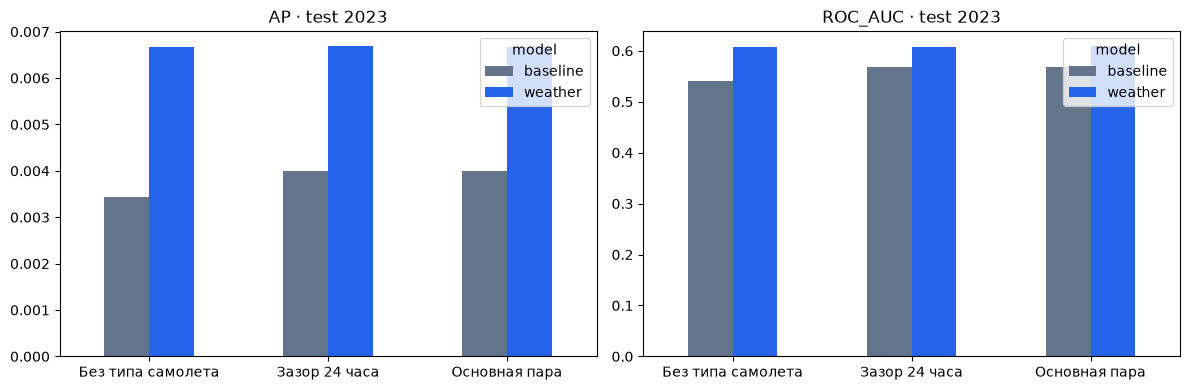

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['AP','ROC_AUC']):
    summary.pivot(index='scenario',columns='model',values=metric).plot.bar(ax=ax,rot=0,color=['#64748b','#2563eb'])
    ax.set_title(metric+' · test 2023');ax.set_xlabel('')
fig.tight_layout()
for ext in ['png','svg']:
    path=BASE/f'figures/05_sensitivity_comparison.{ext}'
    fig.savefig(path,dpi=160,bbox_inches='tight')
    if ext=='svg':path.write_text('\n'.join(s.rstrip() for s in path.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')
plt.show()


## Границы вывода

Эти проверки характеризуют устойчивость внутри заданного семейства моделей
и ретроспективной выборки. Они не подтверждают причинность, эксплуатационную
пригодность или доступность METAR в реальном времени. Зависимость между днями
bootstrap полностью не устраняет. Следующая проверка — изменение задержек
0/30 минут и исключение COR при фиксированном классификаторе и порогах.
